In [2]:
# download customer churn dataset from kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\devku\.cache\kagglehub\datasets\blastchar\telco-customer-churn\versions\1


## Task 1: Exploratory Data Analysis

### 1) Data Cleaning
#### 1.1) Handling empty values

In [3]:
import pandas as pd

data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv") # load csv into dataframe
print("Dataset information:")
print(data.info()) # print info about the dataset

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

In [4]:
'''conduct basic check for null values in the dataset'''
print("Null-value check for each cell in the dataset:")
print(data.isnull())

Null-value check for each cell in the dataset:
      customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0          False   False          False    False       False   False   
1          False   False          False    False       False   False   
2          False   False          False    False       False   False   
3          False   False          False    False       False   False   
4          False   False          False    False       False   False   
...          ...     ...            ...      ...         ...     ...   
7038       False   False          False    False       False   False   
7039       False   False          False    False       False   False   
7040       False   False          False    False       False   False   
7041       False   False          False    False       False   False   
7042       False   False          False    False       False   False   

      PhoneService  MultipleLines  InternetService  OnlineSecurity  ...  \
0            

In [5]:
'''conduct specific check for empty strings through regex while excluding numerical columns'''
print("Empty-string check for non-numeric columns:")
for i in data.select_dtypes(exclude='number').columns: # iterate through all numeric columns
    print(f'Column {i}: {data[i].str.contains(r"^\s*$").unique()}') # print value counts for each column

Empty-string check for non-numeric columns:
Column customerID: [False]
Column gender: [False]
Column Partner: [False]
Column Dependents: [False]
Column PhoneService: [False]
Column MultipleLines: [False]
Column InternetService: [False]
Column OnlineSecurity: [False]
Column OnlineBackup: [False]
Column DeviceProtection: [False]
Column TechSupport: [False]
Column StreamingTV: [False]
Column StreamingMovies: [False]
Column Contract: [False]
Column PaperlessBilling: [False]
Column PaymentMethod: [False]
Column TotalCharges: [False  True]
Column Churn: [False]


In [6]:
'''Identification of correlation between Tenure and TotalCharges'''
# check if str col has any alphabetical characters 
try:
    totalChargeAlphabets = data[data['TotalCharges'].str.contains(r'[a-zA-Z]|^\s*$')] # seperate rows with non-numeric and missing values in TotalCharges col
except AttributeError:
    print('"TotalCharges" is already a numeric column.')
except Exception as e:
    print(f'An error occurred: {e}')

print(totalChargeAlphabets['tenure'],totalChargeAlphabets['TotalCharges']) # print both tenure and totalCharges to view the connection


488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64 488      
753      
936      
1082     
1340     
3331     
3826     
4380     
5218     
6670     
6754     
Name: TotalCharges, dtype: str


In [7]:
'''replace TotalCharge from ' ' to 0 where tenure is 0'''
data.loc[(data['TotalCharges'] == ' ') & (data['tenure'] == 0), 'TotalCharges'] = f'{0.0}'
data['TotalCharges'] = data['TotalCharges'].astype(float)

print("TotalCharges data type after conversion:")
print(data['TotalCharges'].dtype) # check if TotalCharges is now a float
print("Rows with zero tenure after replacing empty TotalCharges values:")
print(data.loc[data['tenure'] == 0.0])

TotalCharges data type after conversion:
float64
Rows with zero tenure after replacing empty TotalCharges values:
      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
488   4472-LVYGI  Female              0     Yes        Yes       0   
753   3115-CZMZD    Male              0      No        Yes       0   
936   5709-LVOEQ  Female              0     Yes        Yes       0   
1082  4367-NUYAO    Male              0     Yes        Yes       0   
1340  1371-DWPAZ  Female              0     Yes        Yes       0   
3331  7644-OMVMY    Male              0     Yes        Yes       0   
3826  3213-VVOLG    Male              0     Yes        Yes       0   
4380  2520-SGTTA  Female              0     Yes        Yes       0   
5218  2923-ARZLG    Male              0     Yes        Yes       0   
6670  4075-WKNIU  Female              0     Yes        Yes       0   
6754  2775-SEFEE    Male              0      No        Yes       0   

     PhoneService     MultipleLines InternetS

In [8]:
#'''Identification of non-numeric values in TotalCharges column'''
#
## check if str col has any alphabetical characters 
#try:
#    totalChargeAlphabets = data[data['TotalCharges'].str.contains(r'[a-zA-Z]|^\s*$')] # seperate rows with non-numeric and missing values in TotalCharges col
#    totalChargeNumeric = data[data['TotalCharges'].str.contains(r'[0-9]')] # seperate rows with numeric values in TotalCharges col
#except AttributeError:
#    print('"TotalCharges" is already a numeric column.')
#except Exception as e:
#    print(f'An error occurred: {e}')
#
#print("Rows with empty or non-numeric values in 'TotalCharges':")
#print(totalChargeAlphabets['TotalCharges']) # print info about the numeric TotalCharges col

In [9]:
#'''replacing non-numeric values in TotalCharges column with column mean after data type conversion to float'''
#
#TCMean = pd.to_numeric(data['TotalCharges'], errors='coerce').mean() # calculate mean of numeric TotalCharges col
#try:
#    mask = data['TotalCharges'].str.contains(r'[a-zA-Z]|^\s*$')
#    data.loc[mask, 'TotalCharges'] = f'{TCMean}'   # rows = mask, column = TotalCharges only
#except AttributeError:
#    print('"TotalCharges" is already a numeric column.')
#except Exception as e:
#    print(f'An error occurred: {e}')
#
#data['TotalCharges'] = data['TotalCharges'].astype(float)
#
#print(f"TotalCharges mean used to replace empty values: {TCMean}")
#print("Rows after replacing empty or non-numeric values in 'TotalCharges':")
#print(data.loc[mask, 'TotalCharges']) # print info about the numeric TotalCharges col

#### 1.2) Handle Duplicate Rows

In [10]:
'''basic duplicate row check'''
print("Basic duplicate row check:")
print(data.duplicated().sum()) # check for duplicate rows if any are available

Basic duplicate row check:
0


In [11]:
'''check for duplicate rows if any are available'''
print("Checking for duplicate rows in the dataset...")
duplicates_before_id_removal = data.duplicated().sum()
print(f"---Duplicate rows before removing customerID: {duplicates_before_id_removal}")

# Remove customerID only if it exists
if 'customerID' in data.columns:
    data.drop(columns=['customerID'], inplace=True)
    print("The customerID column was removed because it identifies individual customers.")
else:
    print("The customerID column was not present in the dataset.")

duplicate_rows = data[data.duplicated()]
print(f"---Duplicate rows after removing customerID: {len(duplicate_rows)}")
if len(duplicate_rows) > 0:
    print("Duplicate rows found and will be removed.")
else:
    print("No duplicate rows were found.")

data.drop_duplicates(inplace=True) # remove duplicate rows if any are available

print(f"---Rows remaining after duplicate removal: {len(data)}")
print(f"---Duplicate rows remaining: {data.duplicated().sum()}")

Checking for duplicate rows in the dataset...
---Duplicate rows before removing customerID: 0
The customerID column was removed because it identifies individual customers.
---Duplicate rows after removing customerID: 22
Duplicate rows found and will be removed.
---Rows remaining after duplicate removal: 7021
---Duplicate rows remaining: 0


C:\Users\devku\AppData\Local\Temp\ipykernel_7736\2454442023.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=['customerID'], inplace=True)
C:\Users\devku\AppData\Local\Temp\ipykernel_7736\2454442023.py:20: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop_duplicates(inplace=True) # remove duplicate rows if any are available


### 2) Data Visualization

#### 2.1) Churn Distribution

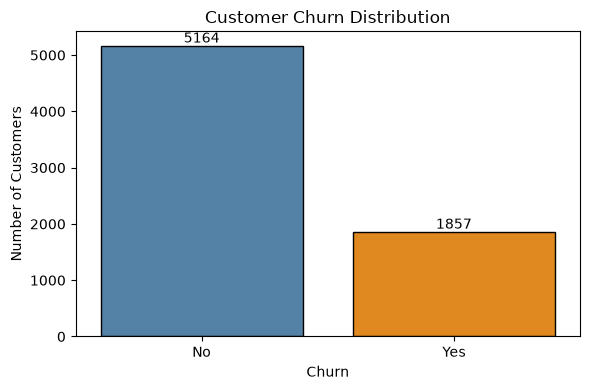

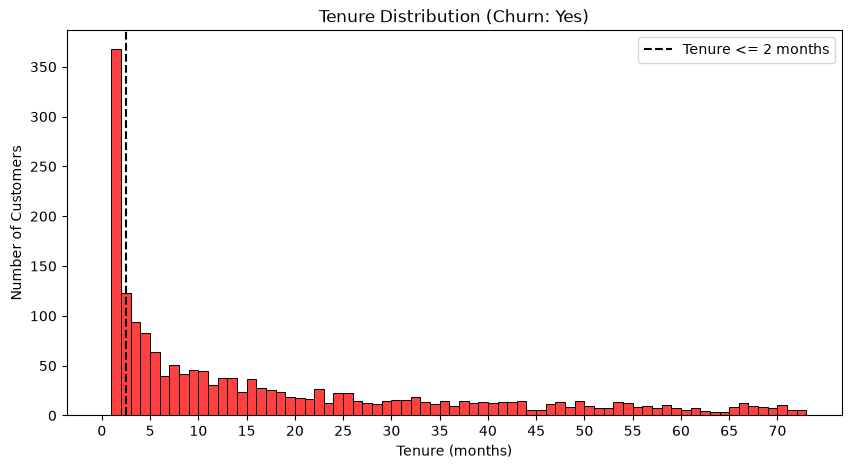

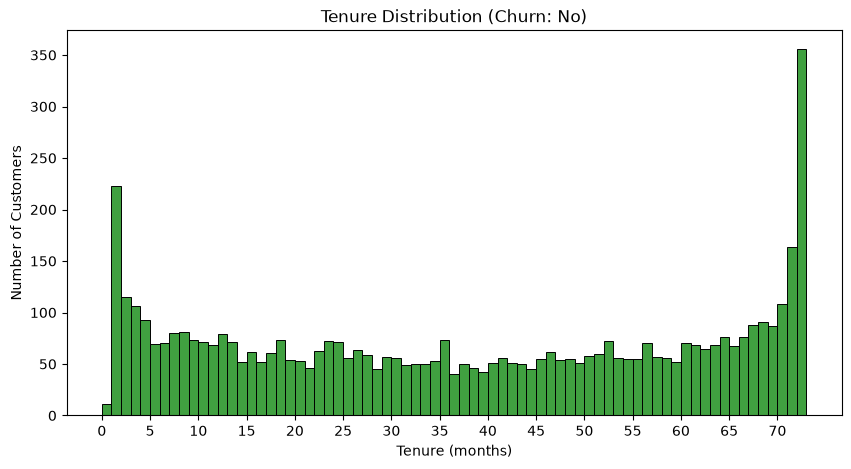

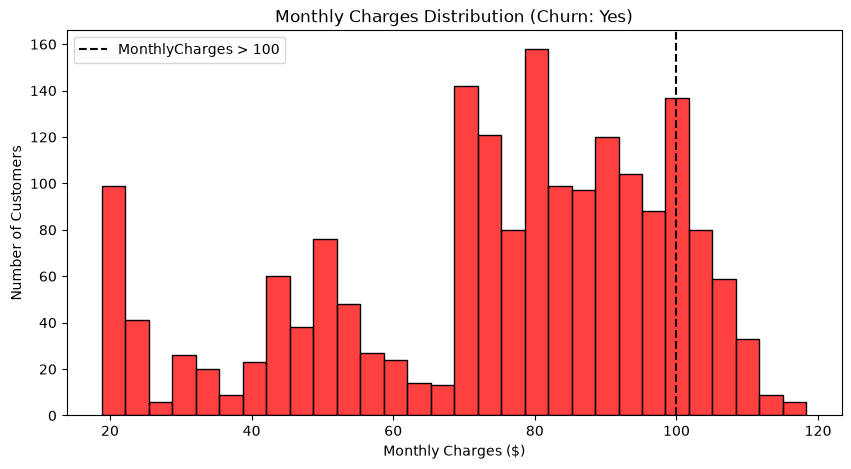

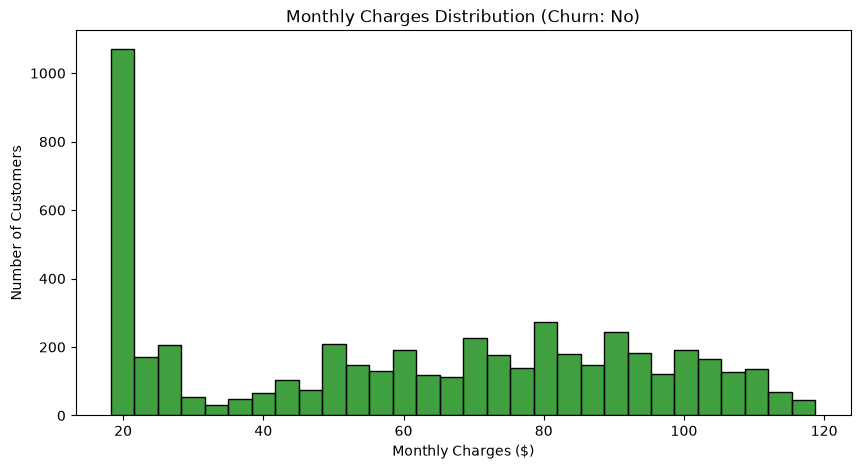

Churn percentages:
Churn
No     73.55
Yes    26.45
Name: proportion, dtype: float64

Data verification:
Churned, tenure <= 2 months: 491
Did not churn, tenure <= 2 months: 349
Churned, MonthlyCharges > 100: 253


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure numeric columns are numeric
data["tenure"] = pd.to_numeric(data["tenure"], errors="coerce")
data["MonthlyCharges"] = pd.to_numeric(
    data["MonthlyCharges"], errors="coerce"
)

# Create consistent masks
churn_yes = data["Churn"].eq("Yes")
churn_no = data["Churn"].eq("No")

early_customer = data["tenure"].le(2)
high_monthly_charge = data["MonthlyCharges"].gt(100)

# -----------------------------
# 1. Overall churn distribution
# -----------------------------

churn_counts = data["Churn"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))

bars = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    hue=churn_counts.index,
    palette=["steelblue", "darkorange"],
    edgecolor="black",
    legend=False,
    ax=ax
).patches

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# -----------------------------
# 2. Tenure distribution
# -----------------------------

# One-month bins: 0, 1, 2, 3, ...
tenure_bins = range(0, int(data["tenure"].max()) + 2)

for churn_status, mask, color in [("Yes", churn_yes, "red"), ("No", churn_no, "green")]:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(
        data.loc[mask, "tenure"].dropna(),
        bins=tenure_bins,
        color=color,
        edgecolor="black",
        stat="count",
        ax=ax
    )
    if churn_status == "Yes":
        ax.axvline(2.5, color="black", linestyle="--", label="Tenure <= 2 months")
        ax.legend()
    ax.set_title(f"Tenure Distribution (Churn: {churn_status})")
    ax.set_xlabel("Tenure (months)")
    ax.set_ylabel("Number of Customers")
    ax.set_xticks(range(0, int(data["tenure"].max()) + 1, 5))

    plt.show()


# -----------------------------
# 3. Monthly charges distribution
# -----------------------------

for churn_status, mask, color in [("Yes", churn_yes, "red"), ("No", churn_no, "green")]:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(
        data.loc[mask, "MonthlyCharges"].dropna(),
        bins=30,
        color=color,
        edgecolor="black",
        stat="count",
        ax=ax
    )
    if churn_status == "Yes":
        ax.axvline(100, color="black", linestyle="--", label="MonthlyCharges > 100")
        ax.legend()
    ax.set_title(f"Monthly Charges Distribution (Churn: {churn_status})")
    ax.set_xlabel("Monthly Charges ($)")
    ax.set_ylabel("Number of Customers")

    plt.show()


# 4. Printed verification metrics
# -----------------------------

churned_early = (churn_yes & early_customer).sum()
not_churned_early = (churn_no & early_customer).sum()
churned_high_charges = (churn_yes & high_monthly_charge).sum()

print("Churn percentages:")
print((data["Churn"].value_counts(normalize=True) * 100).round(2))

print("\nData verification:")
print("Churned, tenure <= 2 months:", churned_early)
print("Did not churn, tenure <= 2 months:", not_churned_early)
print("Churned, MonthlyCharges > 100:", churned_high_charges)

#### 2.2) Numerical variable Distribution

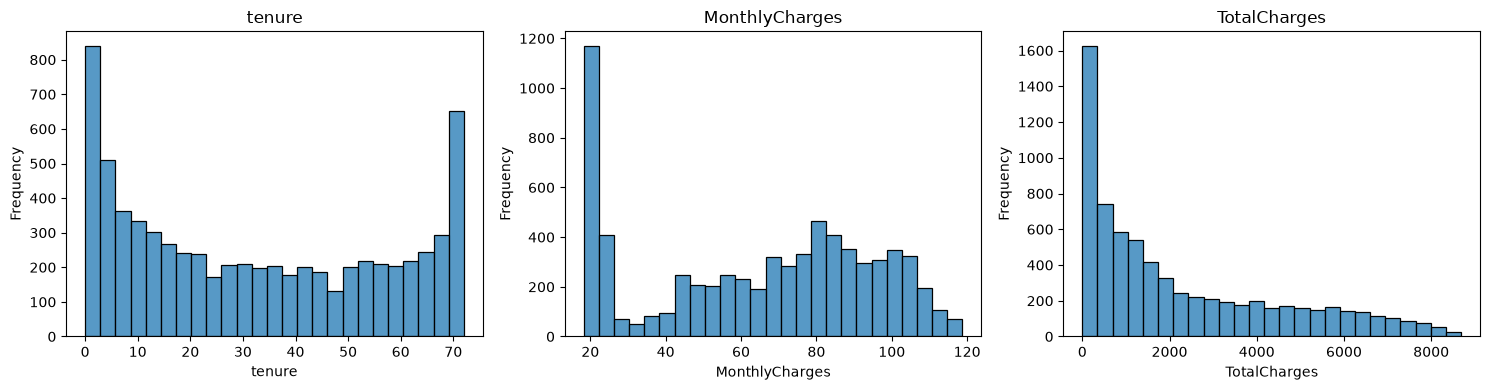

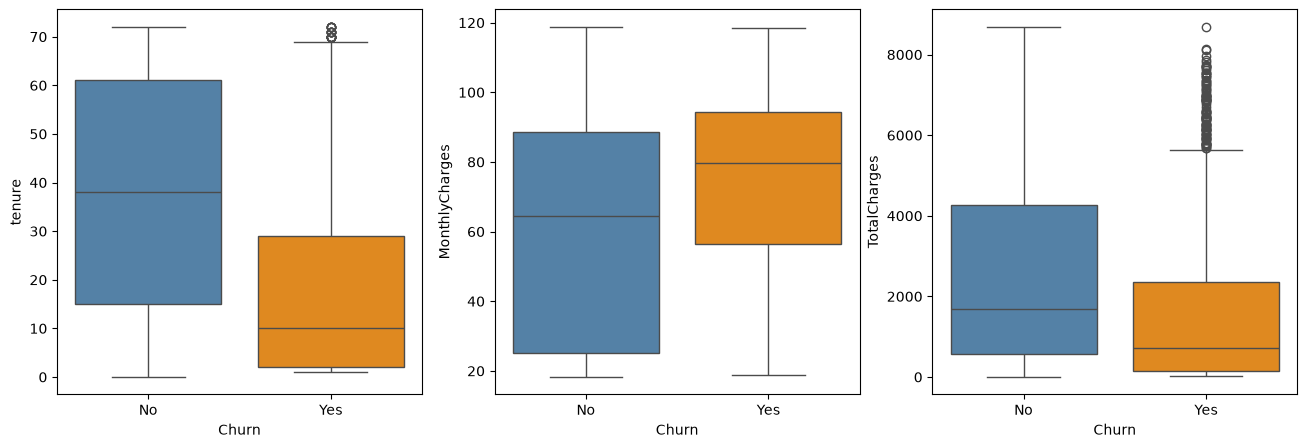

In [13]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numeric_columns):
    sns.histplot(data[column].dropna(), bins=25, edgecolor="black", ax=ax)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(
        data=data,
        x="Churn",
        y=column,
        hue="Churn",
        palette={"No": "steelblue", "Yes": "darkorange"},
        legend=False,
        ax=ax
    )

plt.show()

histograms provide an overview of frequency.
Characteristics of customers who churn:
    much lower tenure compared to customers who dont churn.
    average monthly charges are higher and huge outliers for some customers for totalcharge

Characteristics of customers who didnt churn:
    much higher tenure
    lower average montly charges and lower total charges compared to churned, including outliers.

#### 2.3) Churn rate by tenure groups

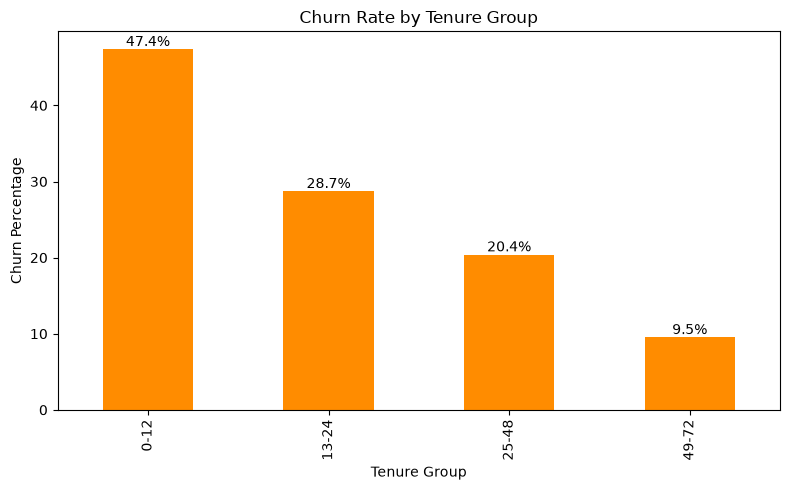

In [14]:
tenureGroup = pd.cut(
    data["tenure"], 
    bins=[-1, 12, 24, 48, 72], 
    labels=["0-12", "13-24", "25-48", "49-72"]
)
churn_rate = data.groupby(tenureGroup, observed=True)["Churn"].apply(lambda v: (v == "Yes").mean() * 100)

fig, ax = plt.subplots(figsize=(8, 5))
churn_rate.plot(kind="bar", ax=ax, color="darkorange")

ax.set_title("Churn Rate by Tenure Group")
ax.set_xlabel("Tenure Group")
ax.set_ylabel("Churn Percentage")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%") # add percentage labels 

plt.tight_layout()
plt.show()

most churn has happened between the 0-12 month range compared to other ranges.

#### 2.4) categorical churn rates

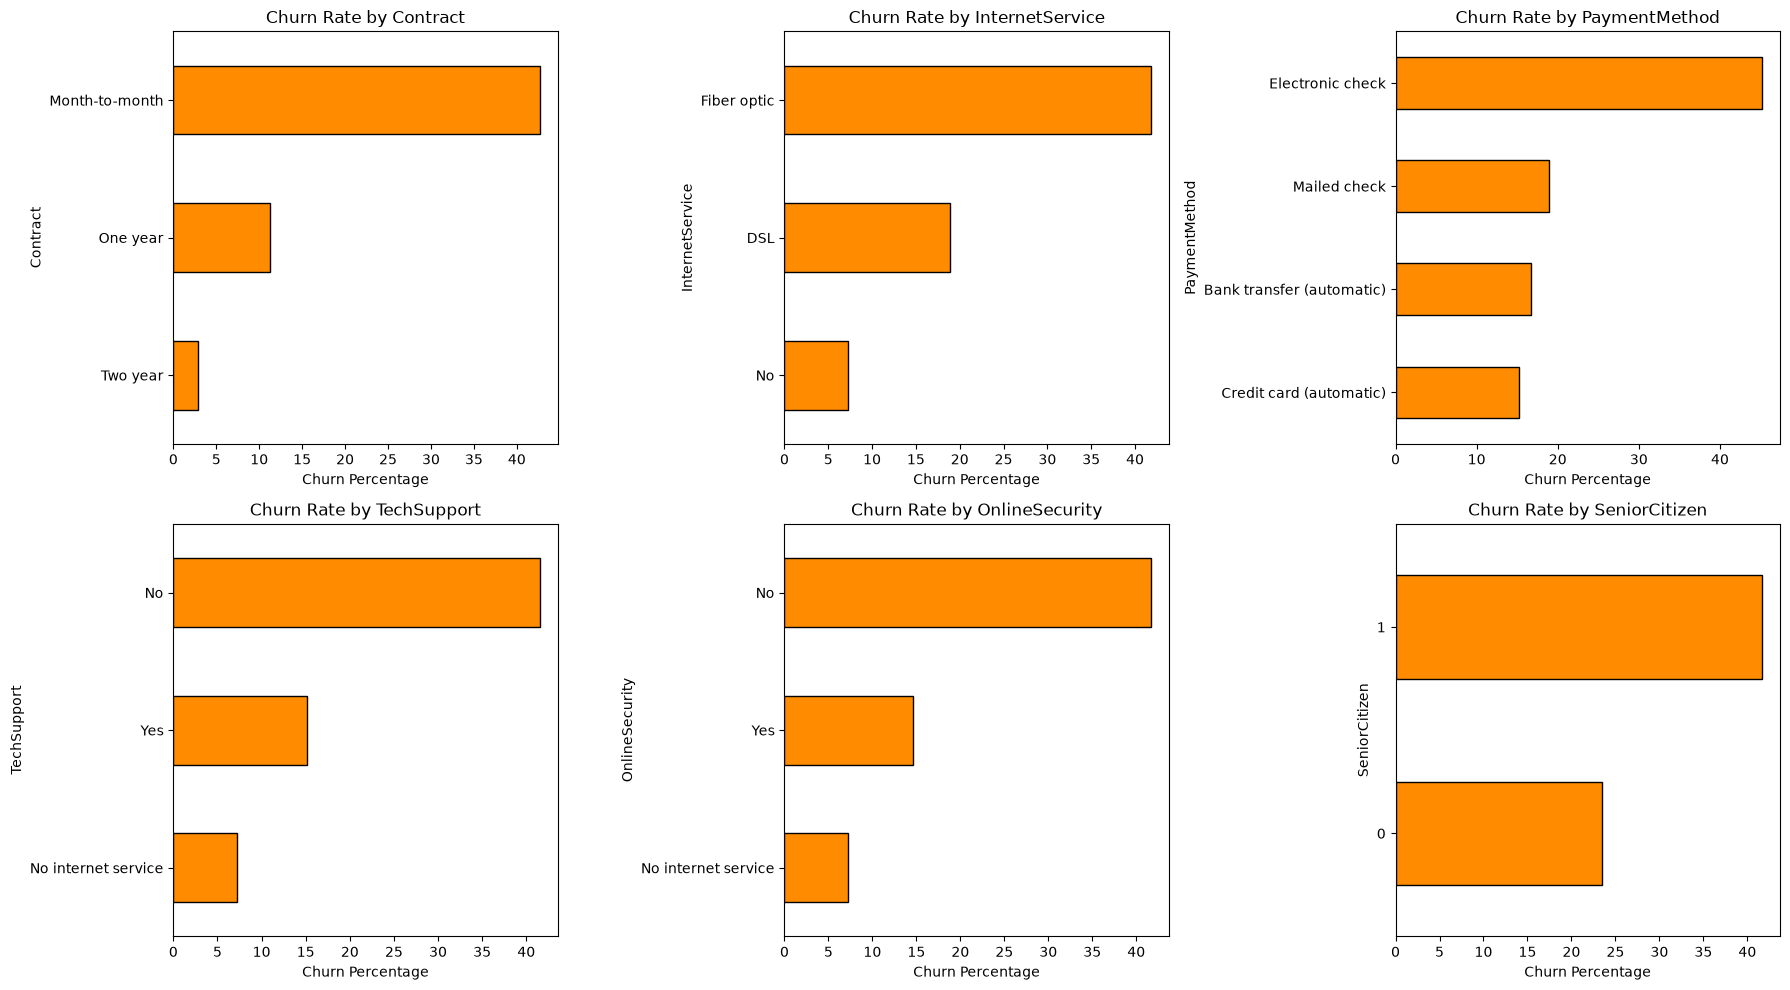

In [15]:
categorical_columns = [ # seperate categorical columns for further analysis
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "SeniorCitizen"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    percentages = (
        pd.crosstab(data[column], data["Churn"], normalize="index") * 100 # create a tabular table for summarised crossed relationship between categories
    )

    percentages["Yes"].sort_values().plot(
        kind="barh",
        ax=ax,
        color="darkorange",
        edgecolor="black"
    )
    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel("Churn Percentage")

plt.tight_layout()
plt.show()

#### 2.5) contract & payment method heatmap

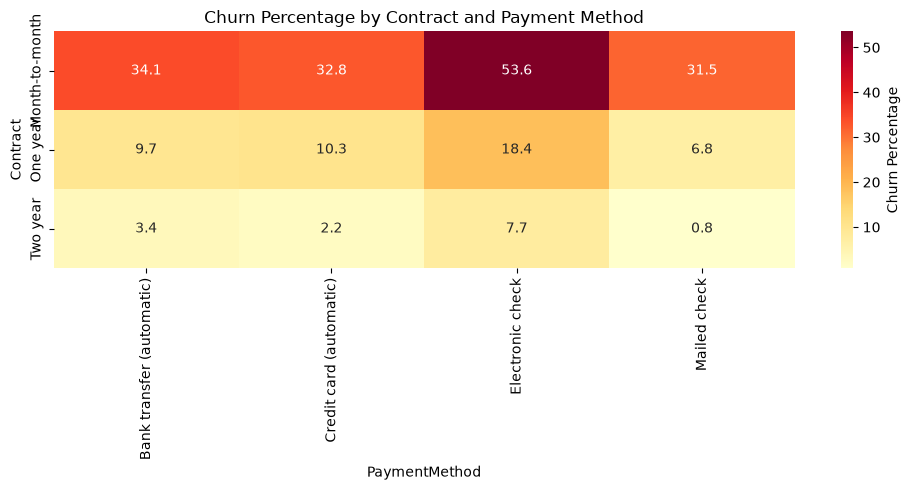

In [16]:
contract_payment = pd.crosstab( # create a tabular table for summarised crossed relationship between categories
    data["Contract"],
    data["PaymentMethod"],
    values=data["Churn"].eq("Yes"),
    aggfunc="mean"
) * 100

plt.figure(figsize=(10, 5))
sns.heatmap(
    contract_payment,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Churn Percentage"}
)
plt.title("Churn Percentage by Contract and Payment Method")
plt.tight_layout()
plt.show()

#### 2.6) correlation analysis between churn and numerical categories

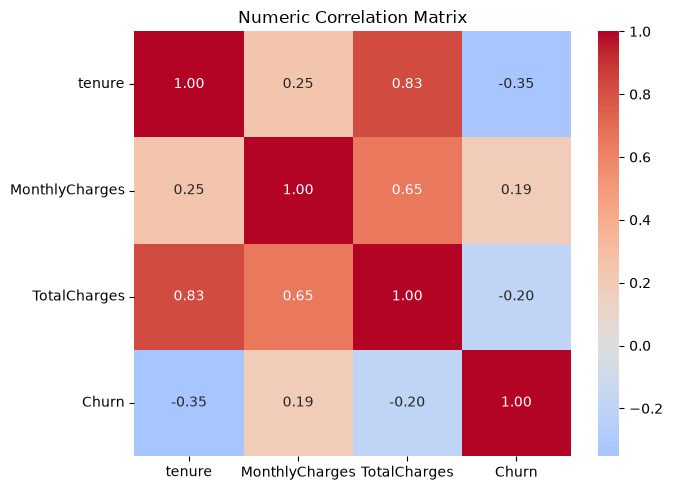

In [17]:
numeric_data = data[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()
numeric_data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

plt.figure(figsize=(7, 5))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Numeric Correlation Matrix")
plt.tight_layout()
plt.show()

## 3) Model implementation

### 3.1) Preprocessing data

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder # scalar for numeric, encoder for catagorical
from sklearn.model_selection import train_test_split

# identify and seperate columns for each type
numericFeatures = ['tenure','MonthlyCharges', 'TotalCharges']
categoricalFeatures = [col for col in data.columns if col not in numericFeatures]; categoricalFeatures.remove('Churn') # remove Churn col

# split train and test data under data distribution seed of 42, 80% train and 20% test, stratify to have matching proportions
xTrain, xTest, yTrain, yTest = train_test_split(
    data.drop(columns=["Churn"]), 
    data["Churn"], 
    test_size=0.2, 
    random_state=42, 
    stratify=data["Churn"]
) 

# define transform plan for each data type, basically what to do
processor = ColumnTransformer([
    ('numerical', StandardScaler(), numericFeatures),
    ('categorical', OneHotEncoder(), categoricalFeatures)
])

xTrainProcessed = processor.fit_transform(xTrain) # fit and transform train data
xTestProcessed = processor.transform(xTest) # transform test data

yTrain = yTrain.map({'No': 0, 'Yes': 1}) # convert yTrain to binary values
yTest = yTest.map({'No': 0, 'Yes': 1}) # convert yTest to binary values

trainSetLen = len(xTrainProcessed) # get length of train data

### 3.2) KNN

In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

knnGridSearch = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={
        'n_neighbors': [5, 13, 21, 29, 31, 37, 43, 51, 57, 63], # use even numbers 
        'weights': ['uniform', 'distance'],
    },
    cv=5,
    scoring='f1',
    n_jobs=-2 # use all except 1 cpu core
)

knnGridSearch.fit(xTrainProcessed, yTrain) # fit the model with train data
print("Best parameters found:", knnGridSearch.best_params_) # print best parameters found

# create model with best parameters
knnModel = KNeighborsClassifier(
    n_neighbors=knnGridSearch.best_params_.get('n_neighbors'),
    weights=knnGridSearch.best_params_.get('weights')
) 
knnModel.fit(xTrainProcessed, yTrain) # fit the model with train data
knnPredictions = knnModel.predict(xTestProcessed) # predict the test data

# Create a separate KNN model with default parameters for comparison.
knnDefaultModel = KNeighborsClassifier()
knnDefaultModel.fit(xTrainProcessed, yTrain)

print(f'Default parameters: n_neighbors={knnDefaultModel.get_params().get("n_neighbors")}, weights={knnDefaultModel.get_params().get("weights")}')

Best parameters found: {'n_neighbors': 31, 'weights': 'uniform'}
Default parameters: n_neighbors=5, weights=uniform


#### 3.2.1) Model Metric Evaluation

In [20]:
tuned_predictions = knnModel.predict(xTestProcessed)
tuned_probabilities = knnModel.predict_proba(xTestProcessed)[:, 1]

knnDefaultPredictions = knnDefaultModel.predict(xTestProcessed)
knnDefaultProbabilities = knnDefaultModel.predict_proba(xTestProcessed)[:, 1]

knn_comparison = pd.DataFrame({
    "Default KNN": [
        accuracy_score(yTest, knnDefaultPredictions),
        precision_score(yTest, knnDefaultPredictions), # rate of identifying actual positives
        recall_score(yTest, knnDefaultPredictions), # rate of avoiding false positives 
        f1_score(yTest, knnDefaultPredictions),
        roc_auc_score(yTest, knnDefaultProbabilities)
    ],
    "Tuned KNN": [
        accuracy_score(yTest, tuned_predictions),
        precision_score(yTest, tuned_predictions), # rate of identifying actual positives
        recall_score(yTest, tuned_predictions), # rate of avoiding false positives 
        f1_score(yTest, tuned_predictions),
        roc_auc_score(yTest, tuned_probabilities)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"])

print("KNN Model Comparison:")
print(knn_comparison.round(4))

KNN Model Comparison:
           Default KNN  Tuned KNN
Accuracy        0.7594     0.7872
Precision       0.5512     0.6137
Recall          0.4919     0.5296
F1-score        0.5199     0.5685
ROC-AUC         0.7724     0.8324


Tuned model is statistically better in all aspects

#### 3.2.2) Visual Evaluation

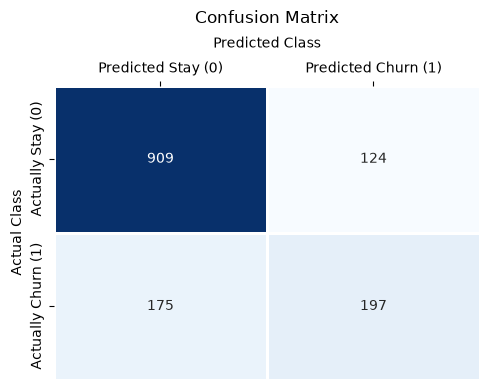

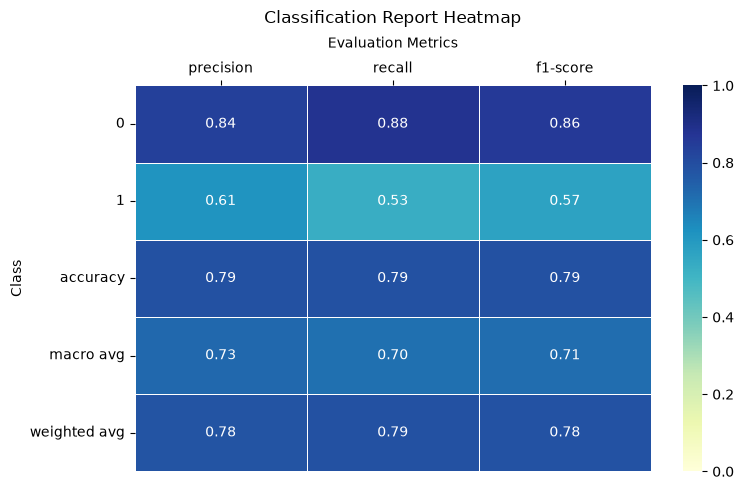

In [21]:
cm = confusion_matrix(yTest, knnPredictions) # confusion matrix plot
plt.figure(figsize=(5, 4))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted Stay (0)", "Predicted Churn (1)"],
    yticklabels=["Actually Stay (0)", "Actually Churn (1)"],

    linewidths=1,
    linecolor="white"
)

# Put x-axis labels at the top
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Predicted Class", labelpad=10)
ax.set_ylabel("Actual Class")

plt.title("Confusion Matrix", pad=45)
plt.tight_layout()
plt.show()

report = classification_report(yTest,knnPredictions,output_dict=True) # classification report plot
report_df = pd.DataFrame(report).transpose() # convert to df
heatmap_data = report_df.drop(columns=["support"]) # remove unwanted col

# Plot classification report heatmap
plt.figure(figsize=(8, 5))

ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Evaluation Metrics", labelpad=10)
ax.set_ylabel("Class")

plt.title("Classification Report Heatmap", pad=45)
plt.tight_layout()
plt.show()

### 3.3) Logistic Regression

In [22]:
from sklearn.linear_model import LogisticRegression

# identify the best parameters for LR for C, penalty, solver, and class_weight
LSGridSearch = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid=[
        {'C': [0.01, 0.1, 1, 10, 100],
         'penalty': ['l1'],
         'solver': ['liblinear', 'saga'],
         'class_weight': [None, 'balanced']},
        {'C': [0.01, 0.1, 1, 10, 100],
         'penalty': ['l2'],
         'solver': ['liblinear', 'sag'],
         'class_weight': [None, 'balanced']}
    ],
    cv=5,
    scoring='f1',
    n_jobs=-2 # use all except 1 cpu core
)

LSGridSearch.fit(xTrainProcessed, yTrain) # fit the model with train data
print("Best parameters found:", LSGridSearch.best_params_) # print best parameters found

LRmodel = LogisticRegression(
    C=LSGridSearch.best_params_.get('C'),
    penalty=LSGridSearch.best_params_.get('penalty'),
    solver=LSGridSearch.best_params_.get('solver'),
    class_weight=LSGridSearch.best_params_.get('class_weight'),
    max_iter=1000
)
LRmodel.fit(xTrainProcessed, yTrain) # fit the model with train data
LRpredictions = LRmodel.predict(xTestProcessed) # predict the test data

# Create a separate Logistic Regression model with default parameters for comparison.
LRDefaultModel = LogisticRegression()
LRDefaultModel.fit(xTrainProcessed, yTrain)

print(f'Default parameters: C={LRDefaultModel.get_params().get("C")}, penalty={LRDefaultModel.get_params().get("penalty")}, solver={LRDefaultModel.get_params().get("solver")}, class_weight={LRDefaultModel.get_params().get("class_weight")}')

Best parameters found: {'C': 1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Default parameters: C=1.0, penalty=deprecated, solver=lbfgs, class_weight=None


c:\Users\devku\OneDrive\Documents\#COLLEGE\Degree\Year 2\Machine Learning\ml_cw\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\devku\OneDrive\Documents\#COLLEGE\Degree\Year 2\Machine Learning\ml_cw\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

#### 3.3.1) Model Metric Evaluation

In [23]:
# Prediction probabilities
LRproba = LRmodel.predict_proba(xTestProcessed)[:, 1]

LRDefaultPredictions = LRDefaultModel.predict(xTestProcessed)
LRDefaultProbabilities = LRDefaultModel.predict_proba(xTestProcessed)[:, 1]

LR_comparison = pd.DataFrame({
    "Default Logistic Regression": [
        accuracy_score(yTest, LRDefaultPredictions),
        precision_score(yTest, LRDefaultPredictions), # rate of identifying actual positives
        recall_score(yTest, LRDefaultPredictions), # rate of avoiding false positives 
        f1_score(yTest, LRDefaultPredictions),
        roc_auc_score(yTest, LRDefaultProbabilities)
    ],
    "Tuned Logistic Regression": [
        accuracy_score(yTest, LRpredictions),
        precision_score(yTest, LRpredictions), # rate of identifying actual positives
        recall_score(yTest, LRpredictions), # rate of avoiding false positives 
        f1_score(yTest, LRpredictions),
        roc_auc_score(yTest, LRproba)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"])

print("Logistic Regression Model Comparison:")
print(LR_comparison.round(4))

print("Best cross-validation F1-score:", LSGridSearch.best_score_)

Logistic Regression Model Comparison:
           Default Logistic Regression  Tuned Logistic Regression
Accuracy                        0.8021                     0.7416
Precision                       0.6610                     0.5079
Recall                          0.5188                     0.7796
F1-score                        0.5813                     0.6151
ROC-AUC                         0.8404                     0.8398
Best cross-validation F1-score: 0.6323608320748523


No real difference between two models for ROC-AUC, the metric which explains the probability of assigning a higher churn score to the customers who churned.

Tuned model is better for recall and f1-score while default is better for accuracy and precision.

#### 3.3.2) Visual Evaluation

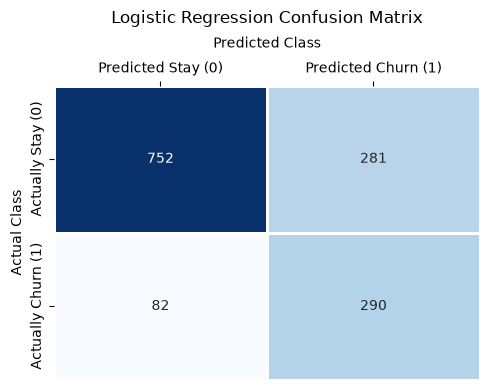

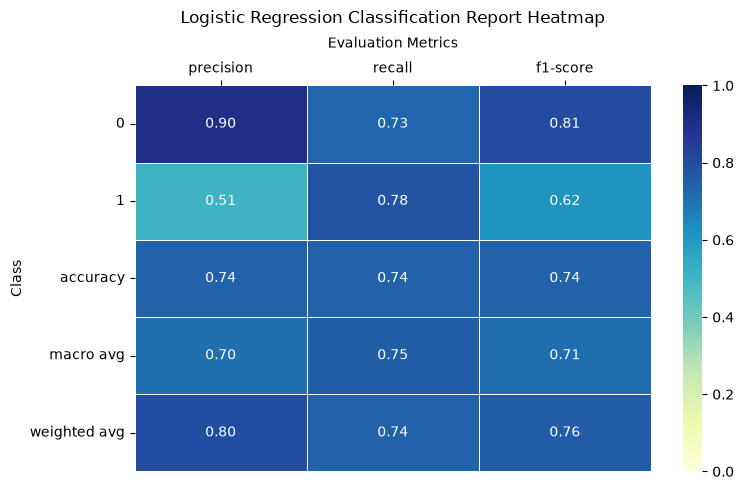

In [24]:
LRcm = confusion_matrix(yTest, LRpredictions)

plt.figure(figsize=(5, 4))

ax = sns.heatmap(
    LRcm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted Stay (0)", "Predicted Churn (1)"],
    yticklabels=["Actually Stay (0)", "Actually Churn (1)"],
    linewidths=1,
    linecolor="white"
)

ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Predicted Class", labelpad=10)
ax.set_ylabel("Actual Class")

plt.title("Logistic Regression Confusion Matrix", pad=45)
plt.tight_layout()
plt.show()

LRreport = classification_report(
    yTest,
    LRpredictions,
    output_dict=True
)

LRreport_df = pd.DataFrame(LRreport).transpose()
LRheatmap_data = LRreport_df.drop(columns=["support"])

plt.figure(figsize=(8, 5))

ax = sns.heatmap(
    LRheatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Evaluation Metrics", labelpad=10)
ax.set_ylabel("Class")

plt.title(
    "Logistic Regression Classification Report Heatmap",
    pad=45
)
plt.tight_layout()
plt.show()

### 3.4) Random Forest

In [25]:
from sklearn.ensemble import RandomForestClassifier

RFGridSearch = GridSearchCV(
    RandomForestClassifier(),
    param_grid={
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'class_weight': [None, 'balanced']
    },
    cv=5,
    scoring='f1',
    n_jobs=-2 # use all except 1 cpu core
)

RFGridSearch.fit(xTrainProcessed, yTrain) # fit the model with train data
print("Best parameters found:", RFGridSearch.best_params_) # print best parameters found

# model with default parameters
RFDefaultModel = RandomForestClassifier()
RFDefaultModel.fit(xTrainProcessed, yTrain)

print(f'Default parameters: n_estimators={RFDefaultModel.get_params().get("n_estimators")}, max_depth={RFDefaultModel.get_params().get("max_depth")}, min_samples_split={RFDefaultModel.get_params().get("min_samples_split")}, class_weight={RFDefaultModel.get_params().get("class_weight")}')

Best parameters found: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Default parameters: n_estimators=100, max_depth=None, min_samples_split=2, class_weight=None


#### 3.4.1) Model Metric Evaluation

In [26]:
# Create predictions using the tuned and default Random Forest models.
RFmodel = RFGridSearch.best_estimator_

RFpredictions = RFmodel.predict(xTestProcessed)
RFproba = RFmodel.predict_proba(xTestProcessed)[:, 1]

RFDefaultPredictions = RFDefaultModel.predict(xTestProcessed)
RFDefaultProbabilities = RFDefaultModel.predict_proba(xTestProcessed)[:, 1]

RF_comparison = pd.DataFrame({
    "Default Random Forest": [
        accuracy_score(yTest, RFDefaultPredictions),
        precision_score(yTest, RFDefaultPredictions),
        recall_score(yTest, RFDefaultPredictions),
        f1_score(yTest, RFDefaultPredictions),
        roc_auc_score(yTest, RFDefaultProbabilities)
    ],
    "Tuned Random Forest": [
        accuracy_score(yTest, RFpredictions),
        precision_score(yTest, RFpredictions),
        recall_score(yTest, RFpredictions),
        f1_score(yTest, RFpredictions),
        roc_auc_score(yTest, RFproba)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"])

print("Random Forest Model Comparison:")
print(RF_comparison.round(4))

print("Best cross-validation F1-score:", RFGridSearch.best_score_)

Random Forest Model Comparison:
           Default Random Forest  Tuned Random Forest
Accuracy                  0.7893               0.7715
Precision                 0.6348               0.5493
Recall                    0.4812               0.7634
F1-score                  0.5474               0.6389
ROC-AUC                   0.8121               0.8390
Best cross-validation F1-score: 0.628543109728224


Tuned model is effectively better except for accuracy and precision.

### 4) Combined Model Evaluation

In [28]:
import numpy as np

# order here = order in the table; None = spacer row
models = {
    "Default KNN":                 (knnDefaultPredictions, knnDefaultProbabilities),
    "Default Logistic Regression": (LRDefaultPredictions,  LRDefaultProbabilities),
    "Default Random Forest":       (RFDefaultPredictions,  RFDefaultProbabilities),
    " ":                           None,
    "Tuned KNN":                   (tuned_predictions,     tuned_probabilities),
    "Tuned Logistic Regression":   (LRpredictions,         LRproba),
    "Tuned Random Forest":         (RFpredictions,         RFproba),
}

rows = {}
for name, vals in models.items():
    if vals is None:
        rows[name] = [np.nan] * 5          # empty spacer row
    else:
        pred, proba = vals
        rows[name] = [
            accuracy_score(yTest, pred),
            precision_score(yTest, pred),
            recall_score(yTest, pred),
            f1_score(yTest, pred),
            roc_auc_score(yTest, proba),
        ]

combined_metrics = pd.DataFrame.from_dict(
    rows, orient="index",
    columns=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
)

# find the spacer row and shrink it so it looks like a thin gap
spacer = list(combined_metrics.index).index(" ") + 1   # nth-child is 1-based

styled = (
    combined_metrics.round(4).style
    .format(precision=4, na_rep="")        # show NaN as blank
    .set_table_styles([{
        "selector": f"tbody tr:nth-child({spacer}) td, tbody tr:nth-child({spacer}) th",
        "props": [("height", "4px"), ("line-height", "4px"),
                  ("padding", "0"), ("font-size", "2px")]
    }])
)

print("Model Comparison:")
display(styled)

Model Comparison:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Default KNN,0.7594,0.5512,0.4919,0.5199,0.7724
Default Logistic Regression,0.8021,0.6610,0.5188,0.5813,0.8404
Default Random Forest,0.7893,0.6348,0.4812,0.5474,0.8121
,,,,,
Tuned KNN,0.7872,0.6137,0.5296,0.5685,0.8324
Tuned Logistic Regression,0.7416,0.5079,0.7796,0.6151,0.8398
Tuned Random Forest,0.7715,0.5493,0.7634,0.6389,0.8390
